In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import funciones_auxiliares_tp2 as aux

FIGURAS = Path("informe") / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

def guardar_figura(fig, nombre: str) -> None:
    """Guarda la figura que usa el informe, en PDF y PNG."""
    for extension in ("pdf", "png"):
        fig.savefig(FIGURAS / f"{nombre}.{extension}", dpi=200, bbox_inches="tight")


## Procesamiento de imágenes

In [ ]:
def cargar_imagen(path: str) -> np.ndarray:
    """
    Carga una imagen desde disco y la devuelve como matriz de intensidades
    en escala de grises de 8 bits (dtype uint8, valores en [0, 255]).
    """
    img = Image.open(path).convert("L")
    return np.array(img, dtype=np.uint8)

def cargar_imagenes(paths: list[str]) -> dict[str, np.ndarray]:
    """
    Carga varias imágenes. Devuelve un diccionario {nombre: matriz}.
    """
    return {p.rsplit(".", 1)[0]: cargar_imagen(p) for p in paths}

def mostrar_imagenes(imagenes: dict[str, np.ndarray]) -> None:
    """
    Muestra las imágenes en escala de grises una al lado de la otra.
    """
    fig, axes = plt.subplots(1, len(imagenes), figsize=(5 * len(imagenes), 4))
    for ax, (nombre, img) in zip(np.atleast_1d(axes), imagenes.items()):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{nombre} ({img.shape[0]}x{img.shape[1]})")
        ax.axis("off")
    plt.tight_layout()
    guardar_figura(fig, "imagenes")
    plt.show()

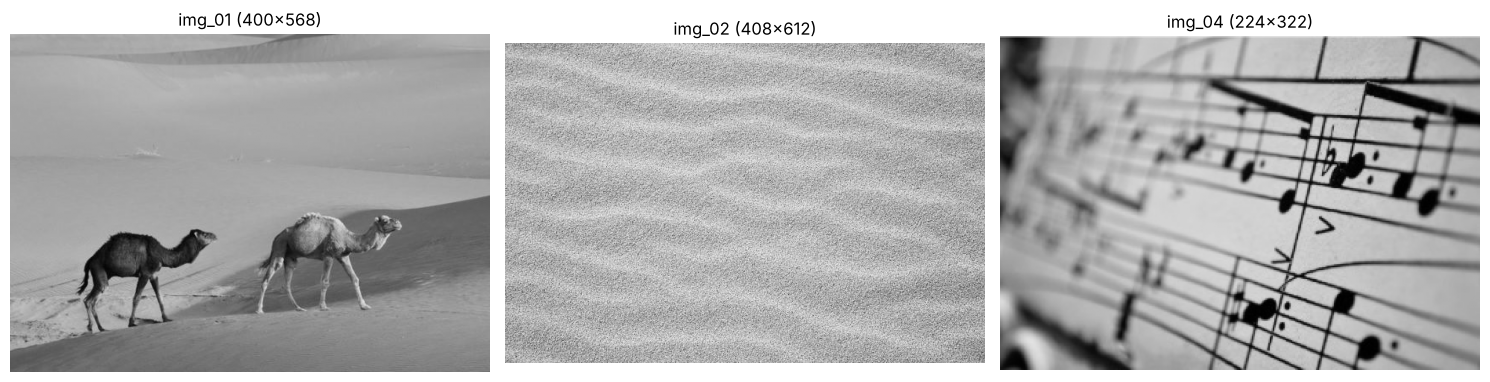

In [3]:
PATHS = ["img_01.jpg", "img_02.jpg", "img_04.jpg"]
imagenes = cargar_imagenes(PATHS)
mostrar_imagenes(imagenes)

## Ejercicio 1

### (a) Masa de probabilidad empírica y entropía

In [ ]:
def estimar_probabilidad(simbolos: np.ndarray, alfabeto: np.ndarray | None = None) -> tuple[np.ndarray, np.ndarray]:
    """
    Estima la masa de probabilidad empírica de una fuente discreta.
    Argumentos:
    --simbolos: arreglo de enteros (cualquier forma). Para una imagen, la matriz de píxeles.
    --alfabeto: valores posibles de la fuente. Si es None se usa {0, ..., 255}.
    Retorno:
    --alfabeto: arreglo con los símbolos.
    --p: arreglo con p(x) = n_x / N para cada símbolo del alfabeto (mismo orden).
    """
    simbolos = np.asarray(simbolos).ravel().astype(np.int64)
    if alfabeto is None:
        alfabeto = np.arange(256)
    alfabeto = np.asarray(alfabeto)

    # Desplazamos para que el símbolo mínimo quede en 0 y poder usar bincount
    offset = alfabeto.min()
    conteos = np.bincount(simbolos - offset, minlength=alfabeto.max() - offset + 1)
    conteos = conteos[alfabeto - offset]
    p = conteos / simbolos.size
    return alfabeto, p


def entropia(p: np.ndarray) -> float:
    """
    Entropía en bits de una masa de probabilidad p. Ignora los términos con p(x) = 0.
    """
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def pmf_a_dict(alfabeto: np.ndarray, p: np.ndarray) -> dict[int, float]:
    """
    Convierte la pmf al formato {símbolo: probabilidad} que espera huffman_code,
    dejando afuera los símbolos de probabilidad nula.
    """
    return {int(x): float(px) for x, px in zip(alfabeto, p) if px > 0}

def graficar_pmf(alfabeto: np.ndarray, p: np.ndarray, titulo: str = "", ax=None, **kwargs):
    """
    Grafica la masa de probabilidad como barras. Si se pasa un eje (ax) dibuja ahí.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(alfabeto, p, width=1.0, **kwargs)
    ax.set_xlabel("símbolo")
    ax.set_ylabel("p")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    return ax

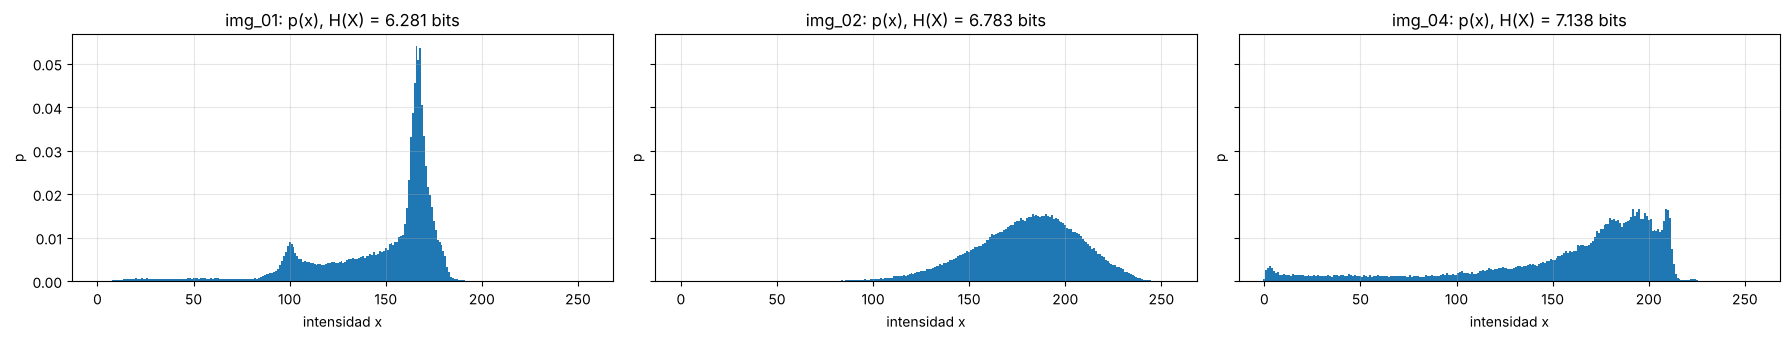

imagen       píxeles  niveles usados   H(X) [bits]
img_01        227200             224        6.2809
img_02        249696             205        6.7826
img_04         72128             228        7.1377


In [5]:
# Estimación de p(x) y H(X) para cada imagen
resultados_1a = {}
fig, axes = plt.subplots(1, len(imagenes), figsize=(6 * len(imagenes), 3.5), sharey=True)

for ax, (nombre, img) in zip(np.atleast_1d(axes), imagenes.items()):
    alfabeto, p_x = estimar_probabilidad(img)
    H_x = entropia(p_x)
    resultados_1a[nombre] = {"alfabeto": alfabeto, "p": p_x, "H": H_x}
    graficar_pmf(alfabeto, p_x, titulo=f"{nombre}: p(x), H(X) = {H_x:.3f} bits", ax=ax)
    ax.set_xlabel("intensidad x")

plt.tight_layout()
guardar_figura(fig, "pmf_x")
plt.show()

print(f"{'imagen':<10}{'píxeles':>10}{'niveles usados':>16}{'H(X) [bits]':>14}")
for nombre, r in resultados_1a.items():
    print(f"{nombre:<10}{imagenes[nombre].size:>10}{int((r['p'] > 0).sum()):>16}{r['H']:>14.4f}")

### (b) Compresión mediante código de Huffman

Caso de un único símbolo: con la función provista la palabra de código quedaría vacía y el decodificador no podría recuperar la cantidad de ocurrencias. Se usa la palabra `0`, por lo que $H(X)=0$ y $L=1$ y la cota estricta $L<H(X)+1$ no se verifica. Con una palabra vacía se podrían usar cero bits de datos, pero habría que guardar la cantidad de símbolos por separado. No se modifican las funciones auxiliares de la cátedra.

In [ ]:
def huffman_encode(simbolos: np.ndarray, codigo: dict[int, str]) -> str:
    """
    Codifica una secuencia de símbolos concatenando las palabras de código.
    Argumentos:
    --simbolos: arreglo de enteros (cualquier forma).
    --codigo: diccionario {símbolo: palabra de código} generado por huffman_code.
    Retorno:
    --Cadena de bits con la secuencia codificada.
    """
    return "".join(codigo[int(s)] for s in np.asarray(simbolos).ravel())


def longitud_media(alfabeto: np.ndarray, p: np.ndarray, codigo: dict[int, str]) -> float:
    """
    Longitud media teórica L = sum_x p(x) l(x) del código.
    """
    return float(sum(px * len(codigo[int(x)]) for x, px in zip(alfabeto, p) if px > 0))


def comprimir_huffman(simbolos: np.ndarray, alfabeto: np.ndarray | None = None) -> dict:
    """
    Estima p, construye el código de Huffman, codifica, decodifica
    y verifica que la reconstrucción sea exacta.
    Retorno: diccionario con p, H, código, bits totales, bits promedio y L.
    """
    simbolos = np.asarray(simbolos)
    alfabeto, p = estimar_probabilidad(simbolos, alfabeto)
    H = entropia(p)
    prob = pmf_a_dict(alfabeto, p)
    # Un único símbolo necesita una palabra no vacía para conservar su cantidad
    # al decodificar con la función provista. Esta convención da H = 0 y L = 1.
    if len(prob) == 1:
        codigo = {next(iter(prob)): "0"}
    else:
        codigo = aux.huffman_code(prob)

    bits = huffman_encode(simbolos, codigo)
    bits_totales = len(bits)
    bits_promedio = bits_totales / simbolos.size
    L = longitud_media(alfabeto, p, codigo)

    decodificado = np.array(aux.huffman_decode(bits, codigo)).reshape(simbolos.shape)
    assert np.array_equal(decodificado, simbolos), "La decodificación no reconstruye la secuencia original"

    return {
        "alfabeto": alfabeto, "p": p, "H": H, "codigo": codigo,
        "bits_totales": bits_totales, "bits_promedio": bits_promedio, "L": L,
    }

In [7]:
resultados_1b = {nombre: comprimir_huffman(img) for nombre, img in imagenes.items()}

print(f"{'imagen':<10}{'H(X)':>9}{'L':>9}{'bits/píxel':>12}{'H(X)+1':>9}{'H<=L<H+1':>10}{'8/L':>8}")
for nombre, r in resultados_1b.items():
    cumple = r["H"] <= r["L"] < r["H"] + 1
    print(f"{nombre:<10}{r['H']:>9.4f}{r['L']:>9.4f}{r['bits_promedio']:>12.4f}"
          f"{r['H'] + 1:>9.4f}{str(cumple):>10}{8 / r['L']:>8.3f}")

imagen         H(X)        L  bits/píxel   H(X)+1  H<=L<H+1     8/L
img_01       6.2809   6.3100      6.3100   7.2809      True   1.268
img_02       6.7826   6.8092      6.8092   7.7826      True   1.175
img_04       7.1377   7.1651      7.1651   8.1377      True   1.117


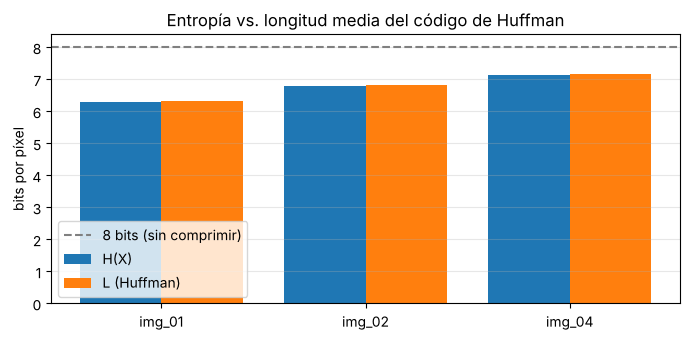

In [ ]:
nombres = list(resultados_1b)
H = [resultados_1b[n]["H"] for n in nombres]
L = [resultados_1b[n]["L"] for n in nombres]
x = np.arange(len(nombres))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(x - 0.2, H, width=0.4, label="H(X)")
ax.bar(x + 0.2, L, width=0.4, label="L (Huffman)")
ax.axhline(8, color="gray", ls="--", label="8 bits (sin comprimir)")
ax.set_xticks(x, nombres)
ax.set_ylabel("bits por píxel")
ax.set_title("Entropía vs. longitud media del código de Huffman")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
guardar_figura(fig, "barras_ej1")
plt.show()

## Ejercicio 2

### (a) Residuos: masa de probabilidad y entropía

In [ ]:
ALFABETO_RESIDUOS = np.arange(-255, 256)

def serpentina(img: np.ndarray) -> np.ndarray:
    """
    Aplana la imagen recorriéndola en serpentina (filas impares invertidas).
    """
    s = img.copy()
    s[1::2] = s[1::2, ::-1]
    return s.ravel()

def deshacer_serpentina(secuencia: np.ndarray, shape: tuple[int, int]) -> np.ndarray:
    """
    Inversa de serpentina: reconstruye la matriz a partir de la secuencia.
    """
    img = secuencia.reshape(shape).copy()
    img[1::2] = img[1::2, ::-1]
    return img

def calcular_residuos(img: np.ndarray) -> tuple[int, np.ndarray]:
    """
    Calcula los residuos y_k = x_k - x_{k-1} sobre el recorrido en serpentina.
    Retorno:
    --inicial: intensidad del primer píxel (condición inicial).
    --residuos: arreglo de enteros en [-255, 255] de longitud M*N - 1.
    """
    seq = serpentina(img).astype(np.int64)
    return int(seq[0]), np.diff(seq)

def reconstruir_desde_residuos(inicial: int, residuos: np.ndarray, shape: tuple[int, int]) -> np.ndarray:
    """
    Reconstruye la imagen sumando sucesivamente los residuos al píxel anterior.
    """
    seq = np.concatenate([[inicial], residuos]).cumsum()
    return deshacer_serpentina(seq, shape).astype(np.uint8)

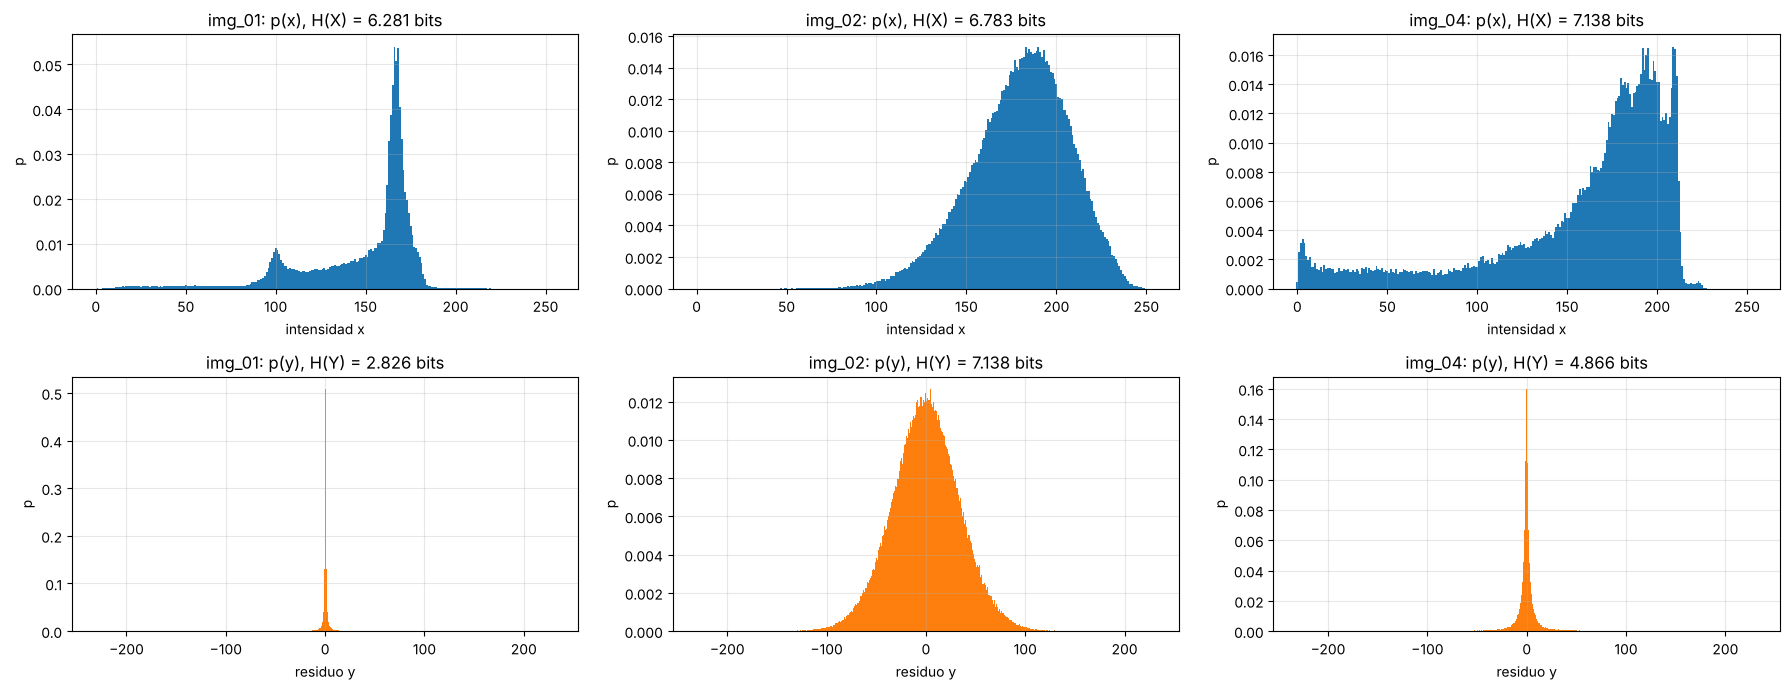

imagen         H(X)     H(Y)  H(X)-H(Y)   |y|<=5  niveles y
img_01       6.2809   2.8262     3.4546    0.925        230
img_02       6.7826   7.1379    -0.3553    0.134        303
img_04       7.1377   4.8659     2.2719    0.719        311


In [10]:
resultados_2a = {}
fig, axes = plt.subplots(2, len(imagenes), figsize=(6 * len(imagenes), 7))

for col, (nombre, img) in enumerate(imagenes.items()):
    inicial, residuos = calcular_residuos(img)
    assert np.array_equal(reconstruir_desde_residuos(inicial, residuos, img.shape), img)

    alfabeto_y, p_y = estimar_probabilidad(residuos, ALFABETO_RESIDUOS)
    H_y = entropia(p_y)
    resultados_2a[nombre] = {"inicial": inicial, "residuos": residuos,
                             "alfabeto": alfabeto_y, "p": p_y, "H": H_y}

    r1 = resultados_1a[nombre]
    graficar_pmf(r1["alfabeto"], r1["p"], titulo=f"{nombre}: p(x), H(X) = {r1['H']:.3f} bits", ax=axes[0, col])
    axes[0, col].set_xlabel("intensidad x")
    graficar_pmf(alfabeto_y, p_y, titulo=f"{nombre}: p(y), H(Y) = {H_y:.3f} bits", ax=axes[1, col], color="C1")
    axes[1, col].set_xlabel("residuo y")
    axes[1, col].set_xlim(-255, 255)

plt.tight_layout()
guardar_figura(fig, "pmf_x_y")
plt.show()

print(f"{'imagen':<10}{'H(X)':>9}{'H(Y)':>9}{'H(X)-H(Y)':>11}{'|y|<=5':>9}{'niveles y':>11}")
for nombre, r in resultados_2a.items():
    p_centro = r["p"][np.abs(r["alfabeto"]) <= 5].sum()
    print(f"{nombre:<10}{resultados_1a[nombre]['H']:>9.4f}{r['H']:>9.4f}"
          f"{resultados_1a[nombre]['H'] - r['H']:>11.4f}{p_centro:>9.3f}{int((r['p'] > 0).sum()):>11}")

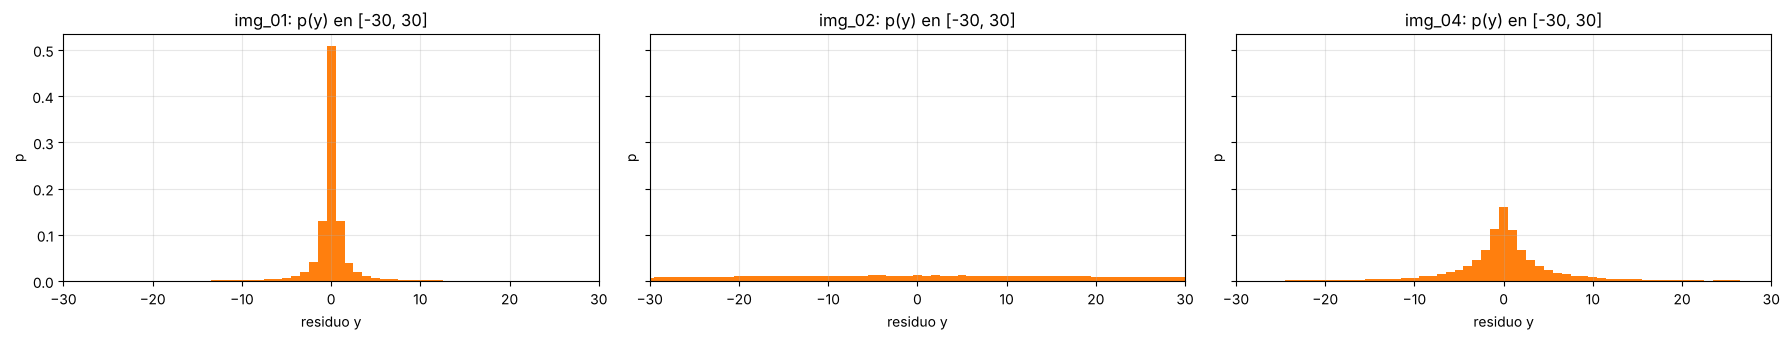

In [ ]:
fig, axes = plt.subplots(1, len(imagenes), figsize=(6 * len(imagenes), 3.5), sharey=True)
for ax, (nombre, r) in zip(np.atleast_1d(axes), resultados_2a.items()):
    graficar_pmf(r["alfabeto"], r["p"], titulo=f"{nombre}: p(y) en [-30, 30]", ax=ax, color="C1")
    ax.set_xlim(-30, 30)
    ax.set_xlabel("residuo y")
plt.tight_layout()
guardar_figura(fig, "pmf_y_zoom")
plt.show()

### (b) Compresión de los residuos mediante Huffman

Se reutiliza `comprimir_huffman` con el alfabeto $\{-255, \dots, 255\}$. Además de los bits por residuo se calcula el costo total por píxel, que suma los 8 bits del píxel inicial.

In [12]:
resultados_2b = {}
for nombre, r in resultados_2a.items():
    res = comprimir_huffman(r["residuos"], ALFABETO_RESIDUOS)
    N = imagenes[nombre].size
    res["bits_totales_imagen"] = 8 + res["bits_totales"]          # píxel inicial + residuos
    res["bits_por_pixel"] = res["bits_totales_imagen"] / N
    resultados_2b[nombre] = res

print(f"{'imagen':<10}{'H(Y)':>9}{'L_Y':>9}{'bits/res':>10}{'H<=L<H+1':>10}"
      f"{'bits/píx':>10}{'L_X (ej1)':>11}{'tasa ej1':>10}{'tasa ej2':>10}")
for nombre, r in resultados_2b.items():
    cumple = r["H"] <= r["L"] < r["H"] + 1
    L_x = resultados_1b[nombre]["L"]
    print(f"{nombre:<10}{r['H']:>9.4f}{r['L']:>9.4f}{r['bits_promedio']:>10.4f}{str(cumple):>10}"
          f"{r['bits_por_pixel']:>10.4f}{L_x:>11.4f}{8 / L_x:>10.3f}{8 / r['bits_por_pixel']:>10.3f}")

imagen         H(Y)      L_Y  bits/res  H<=L<H+1  bits/píx  L_X (ej1)  tasa ej1  tasa ej2
img_01       2.8262   2.8402    2.8402      True    2.8402     6.3100     1.268     2.817
img_02       7.1379   7.1788    7.1788      True    7.1788     6.8092     1.175     1.114
img_04       4.8659   4.8936    4.8936      True    4.8937     7.1651     1.117     1.635


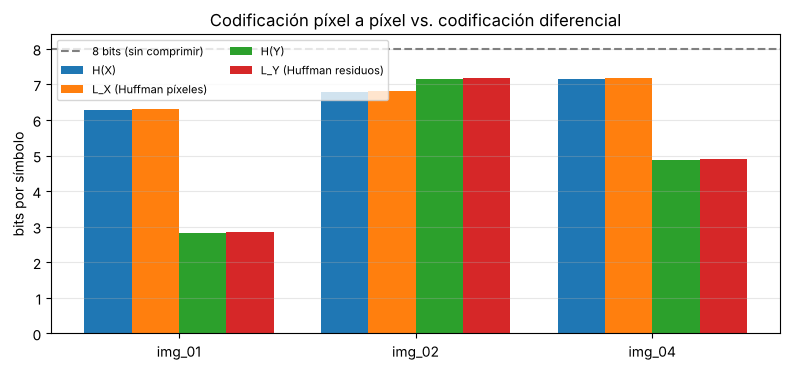

In [ ]:
nombres = list(resultados_2b)
x = np.arange(len(nombres))
w = 0.2
series = [
    ("H(X)", [resultados_1b[n]["H"] for n in nombres]),
    ("L_X (Huffman píxeles)", [resultados_1b[n]["L"] for n in nombres]),
    ("H(Y)", [resultados_2b[n]["H"] for n in nombres]),
    ("L_Y (Huffman residuos)", [resultados_2b[n]["L"] for n in nombres]),
]

fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (etiqueta, valores) in enumerate(series):
    ax.bar(x + (k - 1.5) * w, valores, width=w, label=etiqueta)
ax.axhline(8, color="gray", ls="--", label="8 bits (sin comprimir)")
ax.set_xticks(x, nombres)
ax.set_ylabel("bits por símbolo")
ax.set_title("Codificación píxel a píxel vs. codificación diferencial")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
guardar_figura(fig, "barras_ej2")
plt.show()

### (c) Información mutua entre píxeles vecinos

Los pares $(x', x)$ son los mismos que generan los residuos. Las marginales $\hat p(x')$ y $\hat p(x)$ se calculan sobre esos $MN-1$ pares y no sobre la imagen completa, para que los tres términos de $I = H(X) + H(X') - H(X, X')$ usen las mismas muestras. Por eso la $H(X)$ de este inciso difiere de la del ejercicio 1 en un solo píxel, aunque coincide en las cifras mostradas.

In [14]:
def pares_vecinos(img: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Pares (x', x) de píxeles vecinos consecutivos en el recorrido en serpentina,
    los mismos pares con los que se calcularon los residuos.
    """
    seq = serpentina(img).astype(np.int64)
    return seq[:-1], seq[1:]


def informacion_mutua(a: np.ndarray, b: np.ndarray, n_niveles: int = 256) -> dict:
    """
    Estima empíricamente I(A; B) = H(A) + H(B) - H(A, B) para dos secuencias de
    enteros en {0, ..., n_niveles - 1} de igual longitud.
    Retorno: diccionario con la pmf conjunta y las entropías involucradas.
    """
    # La pmf conjunta se estima reutilizando estimar_probabilidad sobre el índice
    # combinado a * n_niveles + b, que identifica cada par (a, b) con un entero.
    _, p_conjunta = estimar_probabilidad(a * n_niveles + b, np.arange(n_niveles ** 2))
    p_conjunta = p_conjunta.reshape(n_niveles, n_niveles)

    _, p_a = estimar_probabilidad(a, np.arange(n_niveles))
    _, p_b = estimar_probabilidad(b, np.arange(n_niveles))

    H_a, H_b, H_ab = entropia(p_a), entropia(p_b), entropia(p_conjunta)
    return {"p_conjunta": p_conjunta, "H_a": H_a, "H_b": H_b, "H_ab": H_ab, "I": H_a + H_b - H_ab}

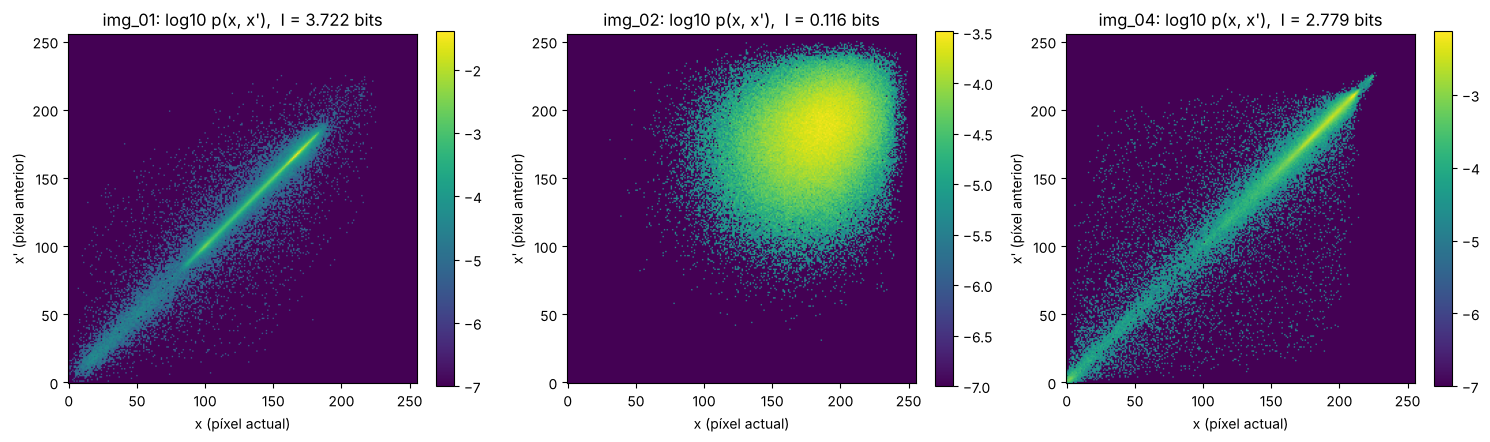

imagen        H(X)  H(X,X´)  I(X;X´)  I/H(X)  H(X|X´)    H(Y)  H(X)-H(Y)
img_01      6.2809   8.8401   3.7217   0.593   2.5592  2.8262     3.4546
img_02      6.7826  13.4495   0.1157   0.017   6.6669  7.1379    -0.3553
img_04      7.1377  11.4959   2.7794   0.389   4.3583  4.8659     2.2718


In [ ]:
resultados_2c = {}
fig, axes = plt.subplots(1, len(imagenes), figsize=(5 * len(imagenes), 4.5))

for ax, (nombre, img) in zip(np.atleast_1d(axes), imagenes.items()):
    x_prev, x_act = pares_vecinos(img)
    r = informacion_mutua(x_prev, x_act)
    resultados_2c[nombre] = r

    im = ax.imshow(np.log10(r["p_conjunta"] + 1e-7), origin="lower", cmap="viridis")
    ax.set_xlabel("x (píxel actual)")
    ax.set_ylabel("x' (píxel anterior)")
    ax.set_title(f"{nombre}: log10 p(x, x'),  I = {r['I']:.3f} bits")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
guardar_figura(fig, "pmf_conjunta")
plt.show()

print(f"{'imagen':<10}{'H(X)':>8}{'H(X,X´)':>9}{'I(X;X´)':>9}{'I/H(X)':>8}{'H(X|X´)':>9}{'H(Y)':>8}{'H(X)-H(Y)':>11}")
for nombre, r in resultados_2c.items():
    H_y = resultados_2a[nombre]["H"]
    H_cond = r["H_b"] - r["I"]
    print(f"{nombre:<10}{r['H_b']:>8.4f}{r['H_ab']:>9.4f}{r['I']:>9.4f}{r['I'] / r['H_b']:>8.3f}"
          f"{H_cond:>9.4f}{H_y:>8.4f}{r['H_b'] - H_y:>11.4f}")

## Ejercicio 3

Las respuestas a las preguntas del ejercicio se desarrollan en la sección 5 del informe.

### Posibles extensiones

Se podría comparar la serpentina horizontal con una vertical o usar predictores causales que combinen
vecinos ya reconstruidos. Habría que medir el resultado: no todos los predictores mejoran todas las imágenes.
Otra opción es una tabla Huffman por valor del vecino para aproximarse a $H(X\mid X')$, contando el
costo de las tablas. Tampoco alcanza esa entropía en general: una condicional $(0.9,0.1)$ tiene
entropía de 0.469 bits y Huffman requiere un bit por símbolo. Con códigos vacíos en contextos
deterministas se cumple $H(X\mid X')\le L_{\rm cond}<H(X\mid X')+1$; si se fuerza un bit en esos
contextos, la cota superior general pasa a ser no estricta.

## Experimento adicional: píxeles mezclados

Se permutan los píxeles de **img_01** con la semilla 42 y se repiten las mismas métricas sobre la imagen resultante (ver sección 6 del informe).

Semilla: 42; histograma y bits directos idénticos
imagen            H(X)       L_X      H(Y)       L_Y     I(X;X´)
original        6.2809    6.3100    2.8262    2.8402      3.7217
mezclada        6.2809    6.3100    7.3711    7.3995      0.1055


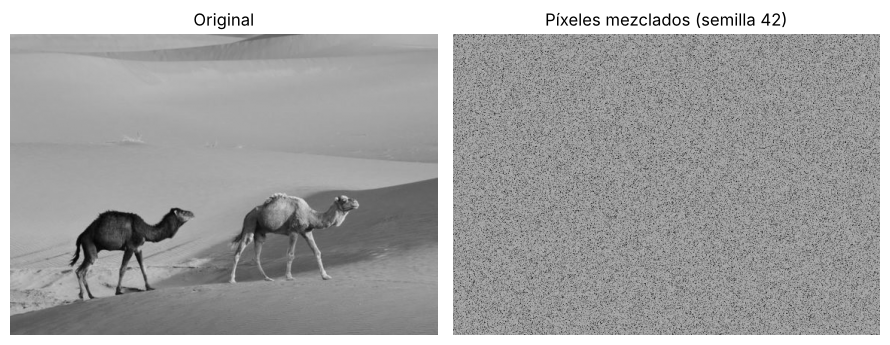

In [16]:
SEMILLA_MEZCLA = 42
original = imagenes["img_01"]
rng = np.random.default_rng(SEMILLA_MEZCLA)
mezclada = rng.permutation(original.ravel()).reshape(original.shape)

assert np.array_equal(np.bincount(original.ravel(), minlength=256),
                      np.bincount(mezclada.ravel(), minlength=256))

resultados_mezcla = {}
for nombre, img in (("original", original), ("mezclada", mezclada)):
    rx = comprimir_huffman(img)
    inicial, residuos = calcular_residuos(img)
    ry = comprimir_huffman(residuos, ALFABETO_RESIDUOS)
    x_prev, x_act = pares_vecinos(img)
    info = informacion_mutua(x_prev, x_act)
    assert np.array_equal(reconstruir_desde_residuos(inicial, residuos, img.shape), img)
    resultados_mezcla[nombre] = {"x": rx, "y": ry, "info": info}

base, mezcla = resultados_mezcla["original"], resultados_mezcla["mezclada"]
assert np.array_equal(base["x"]["p"], mezcla["x"]["p"])
assert base["x"]["bits_totales"] == mezcla["x"]["bits_totales"]

print(f"Semilla: {SEMILLA_MEZCLA}; histograma y bits directos idénticos")
print(f"{'imagen':<12}{'H(X)':>10}{'L_X':>10}{'H(Y)':>10}{'L_Y':>10}{'I(X;X´)':>12}")
for nombre, r in resultados_mezcla.items():
    print(f"{nombre:<12}{r['x']['H']:>10.4f}{r['x']['L']:>10.4f}"
          f"{r['y']['H']:>10.4f}{r['y']['L']:>10.4f}{r['info']['I']:>12.4f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, titulo, img in zip(axes, ("Original", "Píxeles mezclados (semilla 42)"), (original, mezclada)):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
guardar_figura(fig, "mezclado")
plt.show()
